# 04.9 · Overfitting, underfitting and the bias–variance trade-off

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/04-trustworthy-models/09-bias-variance/lesson.ipynb)

Read the [README](README.md) first and do the two-model calculation on paper. This notebook checks it, then *shows* bias and variance by retraining models on 100 different samples, and finally uses learning and validation curves to diagnose the real churn models.

## 1. The by-hand example

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

truth = 100                                   # the customer's real next-month spend
A = np.array([90, 92, 88, 90])                # simple model, retrained on 4 different samples
B = np.array([120, 80, 110, 90])              # flexible model, retrained on the same 4 samples

for name, preds in [("A (simple)", A), ("B (flexible)", B)]:
    bias = preds.mean() - truth
    variance = ((preds - preds.mean()) ** 2).mean()
    mse = ((preds - truth) ** 2).mean()
    print(f"{name:<13} mean {preds.mean():.0f}  bias {bias:+.0f}  bias² {bias**2:.0f}  "
          f"variance {variance:.0f}  →  bias²+var {bias**2 + variance:.0f}   MSE {mse:.0f}")

A (simple)    mean 90  bias -10  bias² 100  variance 2  →  bias²+var 102   MSE 102
B (flexible)  mean 100  bias +0  bias² 0  variance 250  →  bias²+var 250   MSE 250


Bias² + variance equals the mean squared error exactly. Model A is consistently wrong (bias); model B is right on average but all over the place (variance). A's total error is smaller.

## 2. Seeing it: retrain on 100 samples

The truth below is a curve (spend rises with visits, then levels off). We draw 100 different samples of 30 customers from it, with noise, and fit polynomials of degree 1, 3 and 9 to each sample. Each thin line is one fitted model.

In [2]:
rng = np.random.default_rng(0)
def true_f(x):
    """The real (unknown) relationship: spend rises with visits, then levels off."""
    return 200 * (1 - np.exp(-x / 4))
x_grid = np.linspace(1.5, 13, 60)          # where we compare models (inside the data range)

def one_sample(n=30, noise=20):
    x = rng.uniform(0.5, 14, n)
    return x, true_f(x) + rng.normal(0, noise, n)

from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

def fit_many(degree, n_models=100):
    preds = []
    for _ in range(n_models):
        x, y = one_sample()
        m = make_pipeline(StandardScaler(), PolynomialFeatures(degree), LinearRegression())
        preds.append(m.fit(x.reshape(-1, 1), y).predict(x_grid.reshape(-1, 1)))
    return np.array(preds)                                  # shape (100 models, 60 grid points)

all_preds = {d: fit_many(d) for d in [1, 3, 9]}

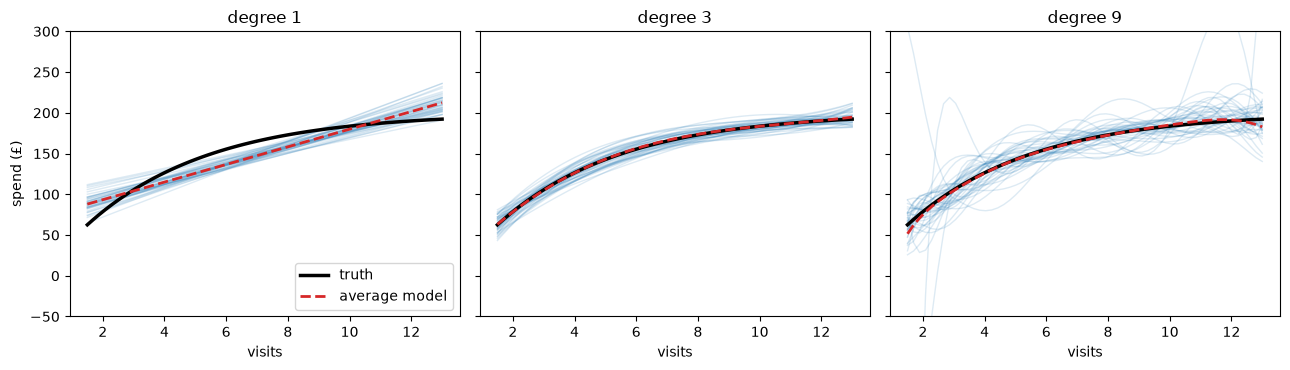

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (d, P) in zip(axes, all_preds.items()):
    for row in P[:40]:
        ax.plot(x_grid, row, color="tab:blue", alpha=.15, lw=1)
    ax.plot(x_grid, true_f(x_grid), color="black", lw=2.5, label="truth")
    ax.plot(x_grid, P.mean(axis=0), color="tab:red", lw=2, ls="--", label="average model")
    ax.set_title(f"degree {d}"); ax.set_xlabel("visits"); ax.set_ylim(-50, 300)
axes[0].set_ylabel("spend (£)"); axes[0].legend(loc="lower right")
plt.tight_layout(); plt.show()

- **Degree 1** (a straight line): every line is similar (low variance), but the average line misses the curve at both ends (high bias). **Underfitting.**
- **Degree 9**: the average follows the truth, but individual models whip around wildly, especially at the edges (high variance). **Overfitting.**
- **Degree 3**: close on average *and* stable. The sweet spot.

Now the numbers, averaged over the 60 grid points:

In [4]:
for d, P in all_preds.items():
    bias2 = ((P.mean(axis=0) - true_f(x_grid)) ** 2).mean()
    var = P.var(axis=0).mean()
    print(f"degree {d}: bias² {bias2:8.1f}   variance {var:8.1f}   bias²+variance {bias2 + var:8.1f}")
print("noise variance (unavoidable): 400.0  (noise std 20)")

degree 1: bias²    179.6   variance     52.2   bias²+variance    231.8
degree 3: bias²      0.5   variance     50.5   bias²+variance     51.0
degree 9: bias²      7.2   variance   2924.8   bias²+variance   2931.9
noise variance (unavoidable): 400.0  (noise std 20)


Degree 1 is dominated by bias (180), degree 9 by variance (about 2,900), and degree 3 has almost none of either (about 51 in total). Expected error on a new customer = bias² + variance + noise. The noise (400 here) is the same for every model; you cannot remove it. You *choose* the balance between the other two.

## 3. Real data: validation curve for tree depth

A **validation curve** varies one complexity setting and plots the training score and the cross-validated score side by side.

In [5]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail

raw = load_retail("Year 2010-2011")                       # ~1 s after the first run
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")                       # features before, target after
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]

cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)        # 1 = did not come back
cust = cust.drop(columns=["first_order", "last_order"])
features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}")

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"train {len(X_train):,} / test {len(X_test):,}")

3,317 customers, churn rate 43.6%


train 2,487 / test 830


In [6]:
from sklearn.model_selection import validation_curve, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
skf = StratifiedKFold(5, shuffle=True, random_state=42)
depths = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20]
tr, va = validation_curve(DecisionTreeClassifier(random_state=42), X_train, y_train,
                          param_name="max_depth", param_range=depths, cv=skf)
for d, a, b in zip(depths, tr.mean(1), va.mean(1)):
    print(f"depth {d:>2}: train {a:.3f}   CV {b:.3f}   gap {a - b:.3f}")

depth  1: train 0.647   CV 0.642   gap 0.005
depth  2: train 0.671   CV 0.659   gap 0.012
depth  3: train 0.681   CV 0.663   gap 0.018
depth  4: train 0.697   CV 0.669   gap 0.029
depth  5: train 0.711   CV 0.674   gap 0.037
depth  6: train 0.729   CV 0.649   gap 0.080
depth  8: train 0.770   CV 0.642   gap 0.127
depth 10: train 0.823   CV 0.631   gap 0.192
depth 15: train 0.937   CV 0.609   gap 0.328
depth 20: train 0.983   CV 0.599   gap 0.384


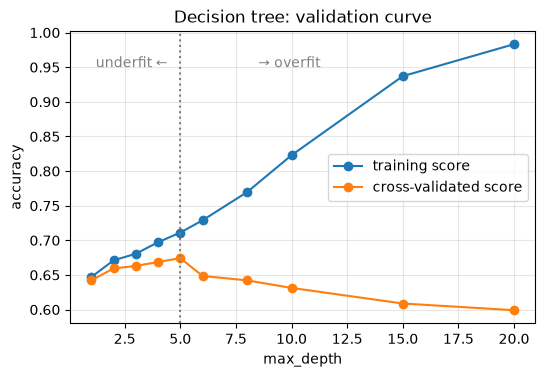

In [7]:
plt.figure(figsize=(6, 3.8))
plt.plot(depths, tr.mean(1), "o-", label="training score")
plt.plot(depths, va.mean(1), "o-", label="cross-validated score")
plt.axvline(5, color="gray", ls=":")
plt.text(1.2, 0.95, "underfit ←", color="gray"); plt.text(8.5, 0.95, "→ overfit", color="gray")
plt.xlabel("max_depth"); plt.ylabel("accuracy"); plt.legend(); plt.grid(alpha=.3)
plt.title("Decision tree: validation curve"); plt.show()

Read it left to right:

- **Depth 1–3**: both scores low and close together. The model is too simple. High bias.
- **Depth 5**: CV score at its peak (0.674). The gap is still small.
- **Depth 6 and beyond**: the training score keeps climbing to 100%; the CV score *falls*. The tree is memorising individual customers. High variance.

## 4. Real data: validation curve for KNN's *k*

For KNN, complexity runs the other way: small *k* is flexible (each prediction depends on one or two neighbours), large *k* is rigid.

In [8]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
ks = [1, 3, 5, 15, 31, 51, 101, 201, 401]
tr_k, va_k = validation_curve(make_pipeline(StandardScaler(), KNeighborsClassifier()), X_train, y_train,
                              param_name="kneighborsclassifier__n_neighbors", param_range=ks, cv=skf)
for k, a, b in zip(ks, tr_k.mean(1), va_k.mean(1)):
    print(f"k={k:>3}: train {a:.3f}   CV {b:.3f}   gap {a - b:.3f}")

k=  1: train 1.000   CV 0.597   gap 0.403
k=  3: train 0.794   CV 0.633   gap 0.161
k=  5: train 0.749   CV 0.643   gap 0.107
k= 15: train 0.700   CV 0.647   gap 0.054
k= 31: train 0.690   CV 0.667   gap 0.023
k= 51: train 0.687   CV 0.672   gap 0.015
k=101: train 0.686   CV 0.682   gap 0.005
k=201: train 0.686   CV 0.680   gap 0.006
k=401: train 0.681   CV 0.674   gap 0.007


At *k* = 1 the training score is (nearly) perfect: every training customer is their own nearest neighbour. That is pure variance. As *k* grows, the gap closes and the CV score rises, then flattens; at very large *k* the model starts drifting towards "predict the majority" (bias).

## 5. Learning curves: would more data help?

A **learning curve** varies the amount of training data instead of the complexity.

logistic regression    at 1989 customers: train 0.685, CV 0.685
unlimited-depth tree   at 1989 customers: train 1.000, CV 0.602


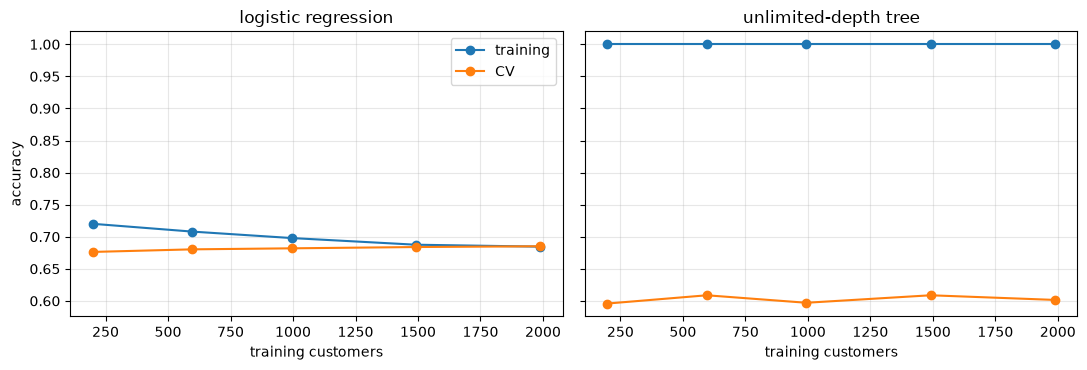

In [9]:
from sklearn.model_selection import learning_curve
from sklearn.linear_model import LogisticRegression
models = {"logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
          "unlimited-depth tree": DecisionTreeClassifier(random_state=42)}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (name, m) in zip(axes, models.items()):
    sizes, tr_s, va_s = learning_curve(m, X_train, y_train, cv=skf, train_sizes=[.1, .3, .5, .75, 1.0])
    ax.plot(sizes, tr_s.mean(1), "o-", label="training"); ax.plot(sizes, va_s.mean(1), "o-", label="CV")
    ax.set_title(name); ax.set_xlabel("training customers"); ax.grid(alpha=.3)
    print(f"{name:<22} at {sizes[-1]} customers: train {tr_s.mean(1)[-1]:.3f}, CV {va_s.mean(1)[-1]:.3f}")
axes[0].set_ylabel("accuracy"); axes[0].legend(); plt.tight_layout(); plt.show()

- **Logistic regression**: the two curves have met at about 0.685. More customers will not help much; the model is as good as its inputs allow. To improve, you need **better features or a more flexible model** (bias problem).
- **Unlimited tree**: training stays at 100%, CV stays near 0.60, with a huge gap at every size. More data would narrow it slowly; **limiting the depth** fixes it now (variance problem).

## 6. The diagnosis table

| What you see | Problem | What helps | What does not |
|---|---|---|---|
| Train and CV both low, close together | High bias (underfit) | More flexible model, better features, less regularisation | More data |
| Train high, CV much lower | High variance (overfit) | Simpler model, regularisation (04.10), more data, fewer features, ensembles (05) | More features |
| Train and CV both high, close | Good fit | Ship it; monitor it | |

## Quiz answers

1. Bias: consistently wrong in the same direction because the model is too simple. Variance: predictions change a lot when retrained on a different sample, because the model is too sensitive.
2. Bias² = 100, variance = 2, MSE = 102.
3. Noise: random variation in the target that no model can predict from the features.
4. Train high, CV much lower: overfitting / high variance. Limit depth, regularise, get more data.
5. No. When the training and CV curves have already met, more of the same data does not raise the plateau; you need better features or a more flexible model.

**Next:** [04.10 Regularisation](../10-regularisation/)